Upload your LA Crime CSV or ZIP file.


Saving clean_crime_data.csv to clean_crime_data (1).csv

Using file: /content/clean_crime_data (1).csv

Original rows: 971,712
Detected date column: Date Occ
Valid records: 971,712
Missing values:
 date           0
crime_type     0
year           0
month          0
day_of_week    0
hour           0
dtype: int64


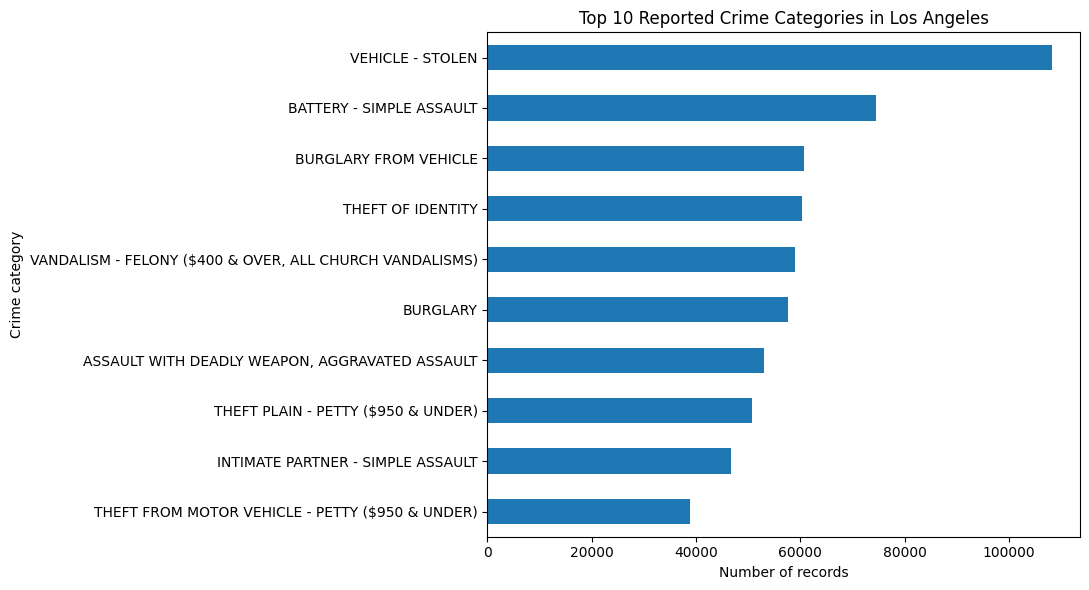


Historical period:
2020-01-01 to 2024-09-01
Number of months: 57


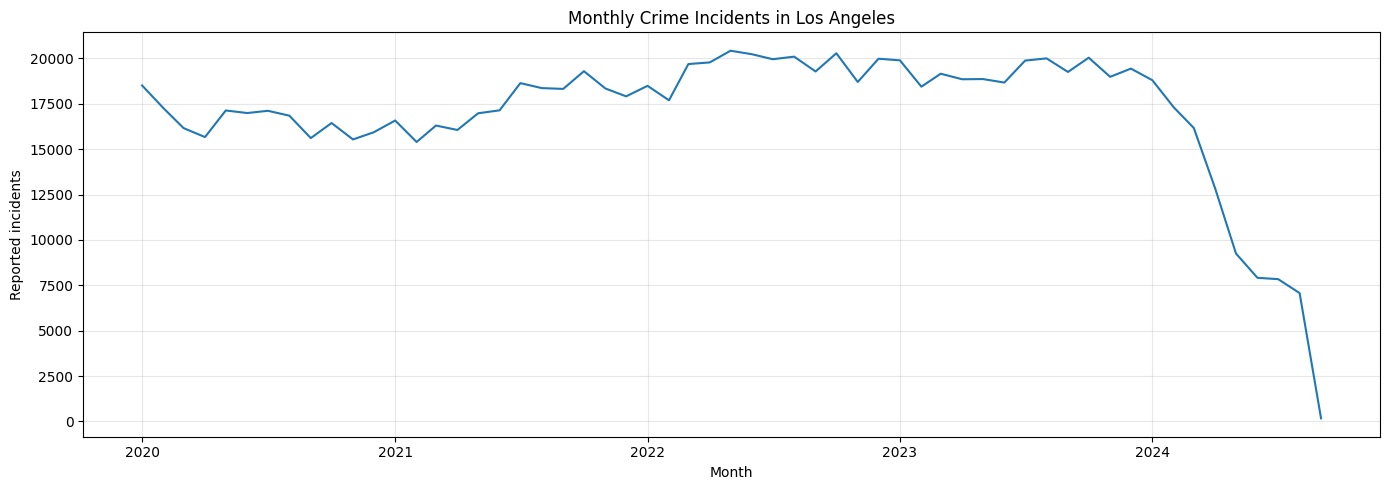

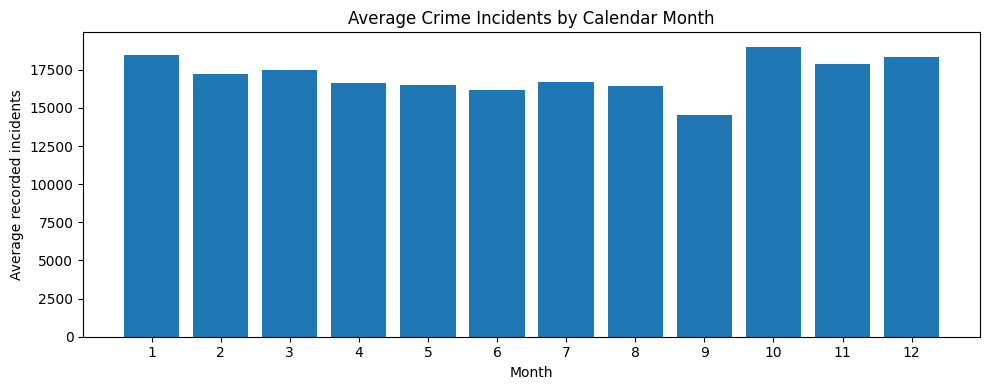


MODEL EVALUATION
-------------------------
MAE:  8,687.41 incidents
RMSE: 10,381.83 incidents


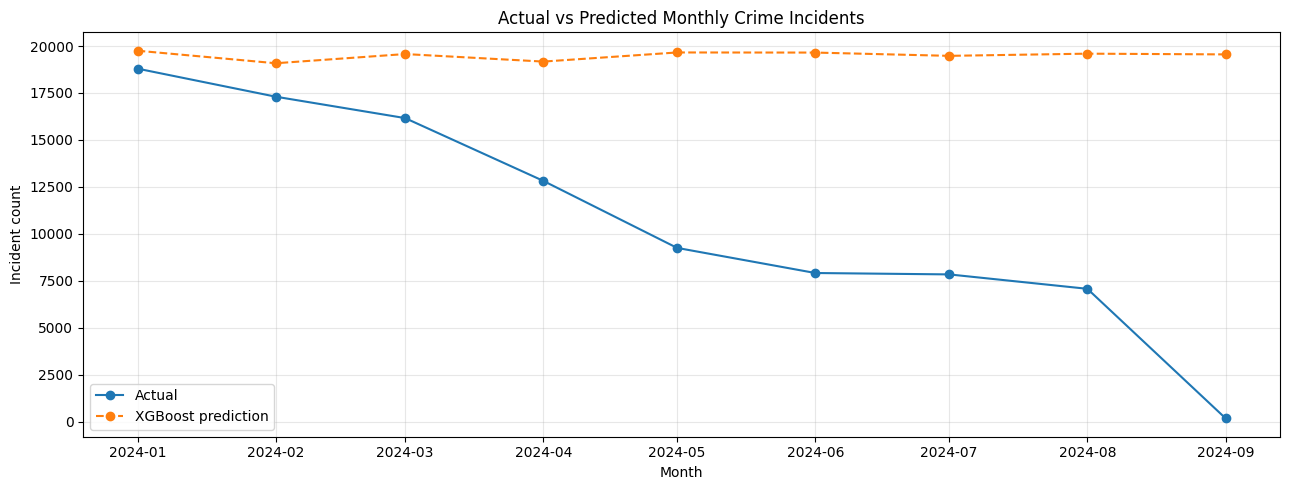


12-MONTH CRIME FORECAST
     month  forecast_crimes
2024-10-01              607
2024-11-01              714
2024-12-01              714
2025-01-01             4850
2025-02-01             4825
2025-03-01             4824
2025-04-01             4995
2025-05-01             5031
2025-06-01             5023
2025-07-01             5011
2025-08-01             4543
2025-09-01              250


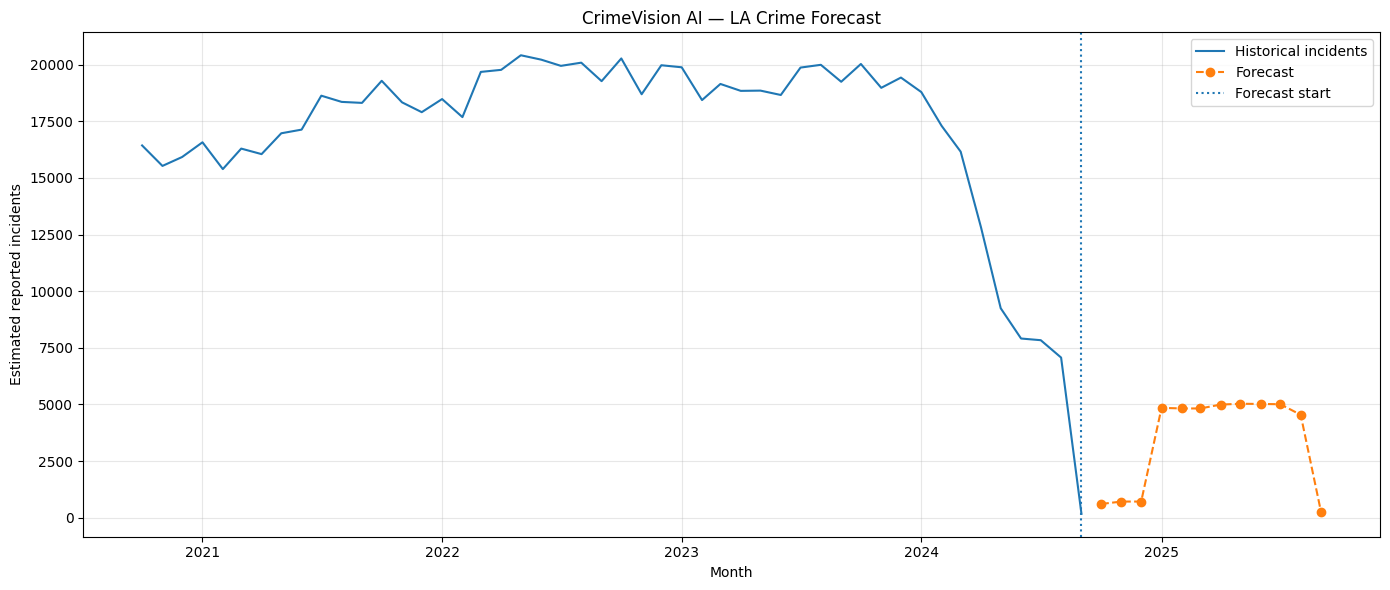

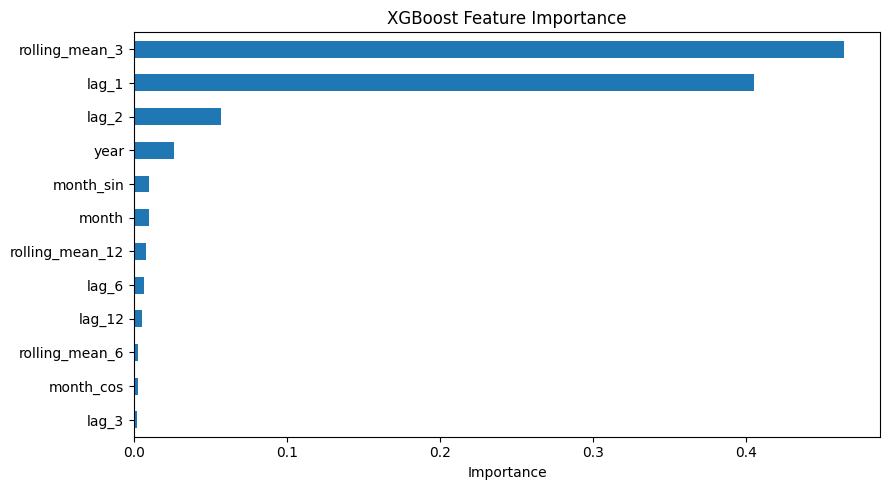


Project completed!
Forecast saved: /content/la_crime_forecast.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [1]:

# ============================================================
# CrimeVision AI
# Los Angeles Crime Analytics & Forecasting
# Google Colab | Pandas | XGBoost | Matplotlib
# ============================================================

!pip -q install xgboost

import os
import glob
import zipfile
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

# ------------------------------------------------------------
# 1. UPLOAD DATASET
# ------------------------------------------------------------

print("Upload your LA Crime CSV or ZIP file.")
uploaded = files.upload()

csv_files = []

for filename in uploaded:
    if filename.lower().endswith(".zip"):
        with zipfile.ZipFile(filename, "r") as z:
            z.extractall("/content/la_crime_data")

    elif filename.lower().endswith(".csv"):
        csv_files.append(os.path.abspath(filename))

csv_files += glob.glob(
    "/content/la_crime_data/**/*.csv", recursive=True
)

csv_files = list(dict.fromkeys(csv_files))

if not csv_files:
    raise FileNotFoundError(
        "No CSV found. Upload the dataset's CSV or ZIP file."
    )

# Choose the largest CSV, usually the main dataset
file_path = max(csv_files, key=os.path.getsize)

print("\nUsing file:", file_path)

# ------------------------------------------------------------
# 2. LOAD AND IDENTIFY COLUMNS
# ------------------------------------------------------------

header = pd.read_csv(file_path, nrows=0)

def normalize(text):
    return (
        str(text).strip().lower()
        .replace("_", " ")
        .replace("-", " ")
    )

column_lookup = {
    normalize(col): col for col in header.columns
}

date_candidates = [
    "date occ", "date occurred", "date",
    "date reported", "date rptd", "datetime"
]

date_col = next(
    (column_lookup[c] for c in date_candidates
     if c in column_lookup),
    None
)

crime_candidates = [
    "crm cd desc", "crime description",
    "crime type", "primary type", "offense description"
]

crime_col = next(
    (column_lookup[c] for c in crime_candidates
     if c in column_lookup),
    None
)

if date_col is None:
    raise ValueError(
        "Date column not found. Available columns: "
        + str(list(header.columns))
    )

usecols = [date_col]

if crime_col and crime_col != date_col:
    usecols.append(crime_col)

df = pd.read_csv(
    file_path,
    usecols=usecols,
    low_memory=False
)

rename_map = {date_col: "date"}

if crime_col:
    rename_map[crime_col] = "crime_type"

df = df.rename(columns=rename_map)

print("\nOriginal rows:", f"{len(df):,}")
print("Detected date column:", date_col)

# ------------------------------------------------------------
# 3. DATA CLEANING
# ------------------------------------------------------------

df["date"] = pd.to_datetime(
    df["date"], errors="coerce"
)

df = df.dropna(subset=["date"]).copy()

# Remove future-dated records
df = df[df["date"] <= pd.Timestamp.now()]

if "crime_type" in df.columns:
    df["crime_type"] = (
        df["crime_type"].astype("string").str.strip()
    )
    df["crime_type"] = df["crime_type"].replace("", pd.NA)

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.day_name()
df["hour"] = df["date"].dt.hour

print("Valid records:", f"{len(df):,}")
print("Missing values:\n", df.isna().sum())

# ------------------------------------------------------------
# 4. CRIME CATEGORY ANALYSIS
# ------------------------------------------------------------

if "crime_type" in df.columns:
    top_crimes = df["crime_type"].value_counts().head(10)

    plt.figure(figsize=(11, 6))
    top_crimes.sort_values().plot(kind="barh")
    plt.title("Top 10 Reported Crime Categories in Los Angeles")
    plt.xlabel("Number of records")
    plt.ylabel("Crime category")
    plt.tight_layout()
    plt.show()

# ------------------------------------------------------------
# 5. MONTHLY TIME SERIES
# ------------------------------------------------------------

monthly = (
    df.set_index("date")
      .resample("MS")
      .size()
      .rename("crime_count")
      .to_frame()
)

# Exclude the incomplete current month
current_month = pd.Timestamp.now().to_period("M").to_timestamp()
monthly = monthly[monthly.index < current_month]

# Retain the observed historical period
positive = np.flatnonzero(
    monthly["crime_count"].to_numpy() > 0
)

if len(positive) == 0:
    raise ValueError("No monthly crime records found.")

monthly = monthly.iloc[
    positive[0]:positive[-1] + 1
].copy()

if len(monthly) < 24:
    raise ValueError(
        "At least 24 months are needed for this analysis."
    )

y = monthly["crime_count"].astype(float)

print("\nHistorical period:")
print(y.index.min().date(), "to", y.index.max().date())
print("Number of months:", len(y))

plt.figure(figsize=(14, 5))
plt.plot(y.index, y.values)
plt.title("Monthly Crime Incidents in Los Angeles")
plt.xlabel("Month")
plt.ylabel("Reported incidents")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 6. SEASONAL ANALYSIS
# ------------------------------------------------------------

seasonality = monthly.groupby(
    monthly.index.month
)["crime_count"].mean()

plt.figure(figsize=(10, 4))
plt.bar(seasonality.index, seasonality.values)
plt.title("Average Crime Incidents by Calendar Month")
plt.xlabel("Month")
plt.ylabel("Average recorded incidents")
plt.xticks(range(1, 13))
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 7. CREATE MACHINE LEARNING FEATURES
# ------------------------------------------------------------

def create_features(series):
    X = pd.DataFrame(index=series.index)

    X["year"] = series.index.year
    X["month"] = series.index.month

    X["month_sin"] = np.sin(
        2 * np.pi * X["month"] / 12
    )
    X["month_cos"] = np.cos(
        2 * np.pi * X["month"] / 12
    )

    for lag in [1, 2, 3, 6, 12]:
        X[f"lag_{lag}"] = series.shift(lag)

    for window in [3, 6, 12]:
        X[f"rolling_mean_{window}"] = (
            series.shift(1).rolling(window).mean()
        )

    return X

X_all = create_features(y)

model_data = X_all.copy()
model_data["target"] = y
model_data = model_data.dropna()

X = model_data.drop(columns="target")
target = model_data["target"]

# ------------------------------------------------------------
# 8. TRAIN AND TEST CHRONOLOGICALLY
# ------------------------------------------------------------

test_size = min(12, max(3, len(model_data) // 5))

X_train = X.iloc[:-test_size]
X_test = X.iloc[-test_size:]

y_train = target.iloc[:-test_size]
y_test = target.iloc[-test_size:]

model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.04,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# Recursive test predictions
history = y.iloc[:-(test_size)]
test_predictions = []

for date in y_test.index:
    temp = pd.concat([
        history,
        pd.Series([np.nan], index=[date])
    ])

    row = create_features(temp).iloc[[-1]]

    prediction = max(
        0, float(model.predict(row)[0])
    )

    test_predictions.append(prediction)
    history.loc[date] = prediction

predictions = pd.Series(
    test_predictions, index=y_test.index
)

# ------------------------------------------------------------
# 9. EVALUATE THE MODEL
# ------------------------------------------------------------

mae = mean_absolute_error(y_test, predictions)

rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

print("\nMODEL EVALUATION")
print("-------------------------")
print(f"MAE:  {mae:,.2f} incidents")
print(f"RMSE: {rmse:,.2f} incidents")

plt.figure(figsize=(13, 5))
plt.plot(
    y_test.index, y_test.values,
    marker="o", label="Actual"
)
plt.plot(
    predictions.index, predictions.values,
    marker="o", linestyle="--",
    label="XGBoost prediction"
)
plt.title("Actual vs Predicted Monthly Crime Incidents")
plt.xlabel("Month")
plt.ylabel("Incident count")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 10. TRAIN FINAL MODEL ON ALL AVAILABLE HISTORY
# ------------------------------------------------------------

final_model = XGBRegressor(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.04,
    subsample=0.9,
    colsample_bytree=0.9,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

final_model.fit(X, target)

# ------------------------------------------------------------
# 11. FORECAST NEXT 12 MONTHS
# ------------------------------------------------------------

history = y.copy()

future_dates = pd.date_range(
    start=y.index[-1] + pd.offsets.MonthBegin(1),
    periods=12,
    freq="MS"
)

future_predictions = []

for date in future_dates:
    temp = pd.concat([
        history,
        pd.Series([np.nan], index=[date])
    ])

    row = create_features(temp).iloc[[-1]]

    prediction = max(
        0, float(final_model.predict(row)[0])
    )

    future_predictions.append(prediction)
    history.loc[date] = prediction

forecast = pd.DataFrame({
    "month": future_dates,
    "forecast_crimes": np.round(
        future_predictions
    ).astype(int)
})

print("\n12-MONTH CRIME FORECAST")
print(forecast.to_string(index=False))

# ------------------------------------------------------------
# 12. HISTORICAL + FUTURE FORECAST CHART
# ------------------------------------------------------------

plt.figure(figsize=(14, 6))

plt.plot(
    y.tail(48).index,
    y.tail(48).values,
    label="Historical incidents"
)

plt.plot(
    future_dates,
    future_predictions,
    marker="o",
    linestyle="--",
    label="Forecast"
)

plt.axvline(
    y.index[-1], linestyle=":",
    label="Forecast start"
)

plt.title("CrimeVision AI — LA Crime Forecast")
plt.xlabel("Month")
plt.ylabel("Estimated reported incidents")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 13. FEATURE IMPORTANCE
# ------------------------------------------------------------

importance = pd.Series(
    final_model.feature_importances_,
    index=X.columns
).sort_values()

plt.figure(figsize=(9, 5))
importance.plot(kind="barh")
plt.title("XGBoost Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 14. EXPORT RESULTS
# ------------------------------------------------------------

output_path = "/content/la_crime_forecast.csv"

forecast.to_csv(output_path, index=False)

print("\nProject completed!")
print("Forecast saved:", output_path)

files.download(output_path)
